Fuente del proyecto original

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/akshayrb22/playing-with-data/blob/master/supervised_learning/KNN/KNN.ipynb)

# K-Nearest Neighbors (KNN) y Ventanas de Parzen


Para el desarrollo y validación de este algoritmo, se utilizó el Breast Cancer Wisconsin (Diagnostic) Dataset, obtenido del repositorio de aprendizaje automático de la UCI (University of California, Irvine).
Este conjunto de datos contiene mediciones obtenidas a partir de imágenes digitalizadas de una aspiración con aguja fina (FNA) de una masa mamaria. Las características describen las propiedades de los núcleos celulares presentes en la imagen.

Instancias totales: 569 registros de pacientes.

Atributos: 30 variables predictoras numéricas

Variable Objetivo: Diagnóstico del tumor.

*   Clase 1 (Maligno): 212 casos (37.3%).
*   Clase 2 (Benigno): 357 casos (62.7%).

Importación de Librerías

In [ ]:
import pandas as pd  # Para cargar y manipular el dataset (tablas)
import numpy as np   # Para manejar arreglos numéricos
import math          # Para funciones matemáticas como la raíz cuadrada
import operator      # Para ordenar los vecinos de menor a mayor distancia
from sklearn.model_selection import KFold  # Para implementar la Validación Cruzada y medir la estabilidad.
from sklearn.preprocessing import StandardScaler # Para normalizar los datos de entrada
import matplotlib.pyplot as plt  # Para generar gráficas, como la superficie de decisión de Parzen.
import seaborn as sns   # Para crear visualizaciones, como el mapa de calor de la matriz.
from sklearn.metrics import confusion_matrix, classification_report # Para calcular métricas de clasificación (Sensibilidad y Exactitud).

***Paso 1. Preparación inicial y limpieza de los datos***

Importación del dataset

In [ ]:
# Definimos la ruta del conjunto de datos (Cáncer de mama de Wisconsin)
url = 'https://raw.githubusercontent.com/melwinlobo18/K-Nearest-Neighbors/master/Dataset/data.csv'

# Cargamos el archivo CSV en un DataFrame de Pandas
df = pd.read_csv(url)

# Convertimos las etiquetas de texto a valores numéricos para el modelo:
# 'M' (Maligno) será 1 y 'B' (Benigno) será 2
df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 2
})

# Creamos una nueva columna llamada 'Class' copiando los valores de diagnóstico
labels = df['diagnosis'].tolist()
df['Class'] = labels

# Eliminamos las columnas que no aportan información relevante para el cálculo (ID y columnas vacías)
df = df.drop(['id', 'Unnamed: 32', 'diagnosis'], axis=1)

# Mostramos los primeros cinco renglones para verificar que los datos estén listos
df.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Class
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Normalización de los datos

In [ ]:
# Seleccionamos solo las variables predictoras (todas menos la columna 'Class')
features = df.drop('Class', axis=1)

# Inicializamos el escalador para estandarizar los datos (media 0 y varianza 1)
scaler = StandardScaler()

# Ajustamos y transformamos las variables predictoras
scaled_features = scaler.fit_transform(features)

# Creamos un nuevo DataFrame con los datos normalizados para mantener el orden
df_scaled = pd.DataFrame(scaled_features, columns=features.columns)

# Agregamos de nuevo la columna de respuesta (Class) al conjunto normalizado
df_scaled['Class'] = df['Class'].values

# Verificamos los datos normalizados (ahora todos están en una escala similar)
df_scaled.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Class
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015,1
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190,1
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391,1
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010,1
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100,1


***Paso 2: Dividir los datos en conjunto de entrenamiento y prueba***

División del Conjunto de Datos

In [ ]:
# Usamos df_scaled (los datos normalizados del paso anterior)
np.random.seed(2) # Puedes cambiar el número de semilla (lo que está entre parentesis) para modificar la manera en la que se distribuyen los datos en los conjuntos

# Creamos la máscara aleatoria sobre el dataframe escalado
msk = np.random.rand(len(df_scaled)) < 0.7

# División de los datos
train = df_scaled[msk]   # Conjunto de Entrenamiento (70%)
test = df_scaled[~msk]   # Conjunto de Prueba (30%)

# Mostramos cuántos ejemplos quedaron en cada grupo
print('Número de observaciones en los datos de entrenamiento: ', len(train))
print('Número de observaciones en los datos de prueba: ', len(test))

Número de observaciones en los datos de entrenamiento:  411
Número de observaciones en los datos de prueba:  158


Visualización de subconjuntos

In [ ]:
train.head() # Muestra las primeras 5 filas de los datos que el modelo usará para aprender.

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Class
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015,1
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190,1
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391,1
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010,1
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100,1


In [ ]:
test.head() #Muestra las primeras 5 filas de los datos que el modelo usará para evaluar.

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Class
15,0.117215,1.919912,0.196105,0.011123,1.248222,1.045345,0.942887,0.637649,1.794006,1.130169,...,1.865014,0.501557,0.110075,1.553167,2.566410,2.064909,0.861731,2.131012,2.779335,1
16,0.156977,0.195555,0.114137,0.084216,0.164372,-0.612909,-0.186433,0.094686,-0.823721,-0.507163,...,0.847240,0.480707,0.452516,0.615079,-0.427264,0.092168,0.704897,0.207471,-0.098963,1
18,1.613970,0.665623,1.566503,1.720997,0.138753,-0.031099,0.742007,1.188093,-0.838325,-1.254241,...,0.847240,2.369129,2.667486,0.825491,0.386359,1.271399,1.891049,-0.214770,-0.432012,1
36,0.034851,0.565559,0.068416,-0.062255,0.133059,0.103456,0.541128,0.182128,0.267911,-0.219390,...,0.762561,0.266249,-0.142361,0.536175,1.078479,1.182165,0.458226,1.116664,0.967238,1
39,-0.183840,0.356123,-0.147009,-0.272150,0.372887,0.400995,0.219721,0.141115,-0.334494,0.197386,...,0.055819,0.001155,-0.246430,1.255083,1.070209,1.107324,1.693103,-0.151676,1.283108,1


***Paso 3: Aplicar el algoritmo KNN y Paso 4: validar la estabilidad del modelo***

1. Función de la Distancia Euclidiana

In [ ]:
def euclideanDistance(instance1, instance2, length):
    """Implementación de la fórmula de distancia para n-dimensiones"""
    distance = 0
    for x in range(length):
        # Sumatoria de (xi - yi)^2
        distance += pow((instance1[x] - instance2[x]), 2)
    return math.sqrt(distance)

2. Selección de los K vecinos más cercanos

In [ ]:
def getNeighbors(trainingSet, testInstance, k):
    """Busca y ordena los k registros más similares"""
    distances = []
    # Determinamos la cantidad de variables predictoras
    length = len(testInstance) - 1

    for x in range(len(trainingSet)):
        # Calculamos distancia del dato de prueba contra cada dato de entrenamiento
        dist = euclideanDistance(testInstance, trainingSet[x], length)
        distances.append((trainingSet[x], dist))

    # Ordenamos de forma ascendente (el más cercano al principio)
    distances.sort(key=operator.itemgetter(1))

    neighbors = []
    for x in range(k):
        neighbors.append(distances[x][0])
    return neighbors

3. Clasificación según la mayoría

In [ ]:
def getResponse(neighbors):
    """Determina la clase ganadora por frecuencia"""
    classVotes = {}
    for x in range(len(neighbors)):
        # La clase está en la última posición del arreglo [-1]
        response = neighbors[x][-1]
        classVotes[response] = classVotes.get(response, 0) + 1

    # Ordenamos los votos de mayor a menor
    sortedVotes = sorted(classVotes.items(), key=operator.itemgetter(1), reverse=True)
    return sortedVotes[0][0]

Calcular el accuracy

In [ ]:
def getAccuracy(testSet, predictions):
    """Calcula el porcentaje de aciertos comparando valores"""
    correct = 0

    for x in range(len(testSet)):
        if testSet[x][-1] == predictions[x]:
            correct += 1

    # Calculamos el porcentaje final
    return (correct / float(len(testSet))) * 100.0

Busqueda para encontrar el mejor valor para K

--- Iniciando Optimización de K ---
K=1: Precisión Promedio = 93.19%
K=3: Precisión Promedio = 96.84%
K=5: Precisión Promedio = 96.11%
K=7: Precisión Promedio = 96.11%
K=9: Precisión Promedio = 95.86%
K=11: Precisión Promedio = 95.62%
K=13: Precisión Promedio = 95.13%

>>> El mejor valor encontrado es K = 3


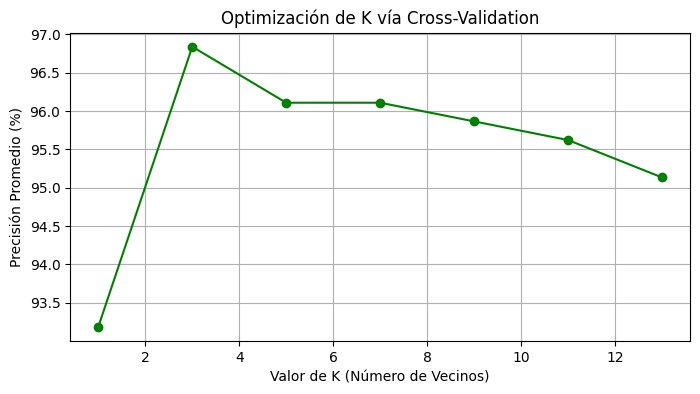

In [ ]:
print("--- Iniciando Optimización de K ---")

# Convertimos el DataFrame de entrenamiento a una lista
datos_entrenamiento = train.values.tolist()

# Definimos los valores de K a probar (usamos solo números impares para evitar empates)
k_values = range(1, 15, 2)
# Variables para guardar el historial de rendimiento
mejor_k = 1
mejor_acc_promedio = 0
historial_acc = []

# Probar cada valor de K definido anteriormente
for k_prueba in k_values:
    # Configuramos Validación Cruzada (K-Fold) con 3 divisiones
    # shuffle=True mezcla los datos antes de dividir para evitar sesgos por orden
    kf = KFold(n_splits=3, shuffle=True, random_state=1)
    puntajes = []

    # Dividimos los datos en 3 partes: 2 para entrenar y 1 para validar en cada iteración
    for idx_train, idx_val in kf.split(datos_entrenamiento):
        # Creamos los subconjuntos de entrenamiento y validación según los índices de KFold
        fold_train = [datos_entrenamiento[j] for j in idx_train]
        fold_val = [datos_entrenamiento[j] for j in idx_val]

        # Generamos predicciones para el conjunto de validación usando el K actual
        predicciones = [getResponse(getNeighbors(fold_train, v, k_prueba)) for v in fold_val]

        # Calculamos la precisión del fold actual y la guardamos
        puntajes.append(getAccuracy(fold_val, predicciones))

    # Calculamos el promedio de precisión de los 3 folds para este valor de K
    acc_promedio = np.mean(puntajes)
    historial_acc.append(acc_promedio)
    print(f"K={k_prueba}: Precisión Promedio = {acc_promedio:.2f}%")
    # Si este K es mejor que el anterior, lo guardamos como el Mejor K
    if acc_promedio > mejor_acc_promedio:
        mejor_acc_promedio = acc_promedio
        mejor_k = k_prueba

print(f"\n>>> El mejor valor encontrado es K = {mejor_k}")

# --- Generación de la Gráfica de Optimización ---
plt.figure(figsize=(8,4))
# Graficamos la precisión promedio para cada valor de K probado
plt.plot(k_values, historial_acc, marker='o', linestyle='-', color='green')
plt.title("Optimización de K vía Cross-Validation")
plt.xlabel("Valor de K (Número de Vecinos)")
plt.ylabel("Precisión Promedio (%)")
plt.grid(True)
plt.show()

En caso de que el usuario quiera usar otro valor de K

In [ ]:
print(f"\n>>> El mejor valor encontrado por Cross-Validation es K = {mejor_k} ({mejor_acc_promedio:.2f}%)")

print("\n--- Configuración Final del Modelo ---")
respuesta = input(f"¿Deseas usar el valor sugerido (K={mejor_k})? (s/n): ").lower()

if respuesta == 's':
    k_final = mejor_k
    print(f"Confirmado: Usaremos K = {k_final}")
else:
    try:
        k_final = int(input("Introduce el valor de K que prefieras usar: "))
        print(f"Entendido: Usaremos tu valor K = {k_final}")
    except ValueError:
        k_final = mejor_k
        print(f"Entrada no válida. Usaremos el sugerido K = {mejor_k} por seguridad.")


>>> El mejor valor encontrado por Cross-Validation es K = 3 (96.84%)

--- Configuración Final del Modelo ---
¿Deseas usar el valor sugerido (K=3)? (s/n): n
Introduce el valor de K que prefieras usar: 12
Entendido: Usaremos tu valor K = 12


Generación de predicciones en el conjunto de prueba

In [ ]:
# Convertimos los conjuntos a listas para el procesamiento manual
training_list = train.values.tolist()
test_list = test.values.tolist()
final_predictions = []
class_names = ['Maligno', 'Benigno']

# Informamos qué K se está utilizando finalmente
print(f"--- Generando predicciones finales con K = {k_final} ---")

# Generamos las predicciones para cada paciente del conjunto de prueba
for i in range(len(test_list)):
    # Usamos k_final (la variable que definimos en el Paso 4)
    vecinos = getNeighbors(training_list, test_list[i], k_final)
    resultado = getResponse(vecinos)
    final_predictions.append(resultado)

# Extraemos las etiquetas reales (columna 'Class') para la comparación
y_real = [row[-1] for row in test_list]

--- Generando predicciones finales con K = 12 ---


***Paso 5: Interpretación de los resultados finales***

Matriz de confusión obtenida en el conjunto de prueba

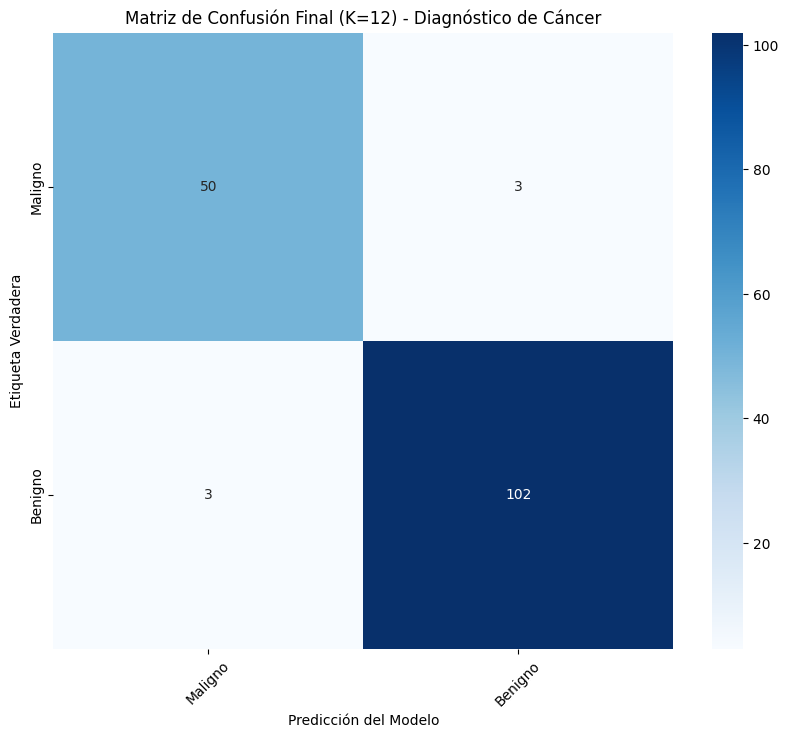


--- Indicadores de Desempeño ---
              precision    recall  f1-score   support

     Maligno       0.94      0.94      0.94        53
     Benigno       0.97      0.97      0.97       105

    accuracy                           0.96       158
   macro avg       0.96      0.96      0.96       158
weighted avg       0.96      0.96      0.96       158

Precisión en Conjunto de Prueba: 96.20%
Precisión Promedio General (K-Fold): 96.84%


In [ ]:
# Visualización de la matriz de confusión
conf_matrix = confusion_matrix(y_real, final_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicción del Modelo')
plt.ylabel('Etiqueta Verdadera')
# Dinamizamos el título para que muestre el K usado
plt.title(f'Matriz de Confusión Final (K={k_final}) - Diagnóstico de Cáncer')
plt.xticks(rotation=45)
plt.show()

# INDICADORES DE DESEMPEÑO
print("\n--- Indicadores de Desempeño ---")
print(classification_report(y_real, final_predictions, target_names=class_names))

# ANÁLISIS DE ESTABILIDAD
precision_test = getAccuracy(test_list, final_predictions)
print(f"Precisión en Conjunto de Prueba: {precision_test:.2f}%")
# Usamos mejor_acc_promedio que viene del Paso 4 para comparar
print(f"Precisión Promedio General (K-Fold): {mejor_acc_promedio:.2f}%")

***Paso 6: Implementación de Ventanas de Parzen***

Este método es una alternativa no paramétrica que estima la densidad de las clases dentro de un área fija denominada ventana.

Función del clasificador de Parzen

In [ ]:
def parzenWindowClassifier(trainingSet, testInstance, h):
    """
    Clasificador de Ventana de Parzen:
    Busca todos los vecinos que se encuentren dentro de un radio fijo 'h'.
    """
    neighbors_in_window = []
    # Calculamos la cantidad de características (sin la clase)
    length = len(testInstance) - 1

    # Recorremos el conjunto de entrenamiento
    for x in range(len(trainingSet)):
        # Usamos la misma función de Distancia Euclidiana del Paso 3
        dist = euclideanDistance(testInstance, trainingSet[x], length)

        # Si la distancia es menor o igual al radio 'h', el dato entra en la ventana
        if dist <= h:
            neighbors_in_window.append(trainingSet[x])

    # Si la ventana está vacía, no se puede clasificar (se puede retornar None o el vecino más cercano)
    if not neighbors_in_window:
        return None

    # Utilizamos la función getResponse para determinar la clase por mayoría en la ventana
    return getResponse(neighbors_in_window)

***Optimización del hiperparámetro h***

In [ ]:
def calcular_h_silverman(datos):
    datos_arr = np.array(datos)
    n, d = datos_arr.shape
    # Usamos la desviación estándar promedio de todas las características
    sigma = np.mean(np.std(datos_arr, axis=0))
    q75, q25 = np.percentile(datos_arr, [75 ,25], axis=0)
    iqr = np.mean(q75 - q25)
    A = min(sigma, iqr / 1.34)
    # Ajuste para d-dimensiones (n^-1/(d+4))
    return A * (n**(-1/(d+4)))

h_sugerido_silverman = calcular_h_silverman(train.values.tolist())

print("--- Iniciando Optimización de h (Parzen con Respaldo KNN) ---")
# Rango de búsqueda: desde muy pequeño hasta un radio amplio
h_values = np.linspace(0.1, 5.0, 20)
mejor_h = 0.1
mejor_acc_parzen = 0
datos_entrenamiento = train.values.tolist()

for h_prueba in h_values:
    # Usamos 5 splits para que el entrenamiento sea más robusto (80% tren / 20% val)
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    puntajes = []

    for idx_train, idx_val in kf.split(datos_entrenamiento):
        fold_train = [datos_entrenamiento[j] for j in idx_train]
        fold_val = [datos_entrenamiento[j] for j in idx_val]

        preds = []
        for v in fold_val:
            # Intentamos Parzen
            res = parzenWindowClassifier(fold_train, v, h_prueba)
            # Si es None (zona gris), usamos 1-NN como respaldo
            if res is None:
                vecinos_respaldo = getNeighbors(fold_train, v, k=1)
                res = getResponse(vecinos_respaldo)
            preds.append(res)

        puntajes.append(getAccuracy(fold_val, preds))

    acc_promedio = np.mean(puntajes)
    if acc_promedio > mejor_acc_parzen:
        mejor_acc_parzen = acc_promedio
        mejor_h = h_prueba

print(f"\n>>> Silverman (Multidim) sugiere: {h_sugerido_silverman:.4f}")
print(f">>> Cross-Validation sugiere: {mejor_h:.2f} ")

--- Iniciando Optimización de h (Parzen con Respaldo KNN) ---

>>> Silverman (Multidim) sugiere: 0.7412
>>> Cross-Validation sugiere: 2.94 


Selección del valor de h, ya sea por Silverman, Validación cruzada o cualquiera que el usuario quiera seleccionar

In [ ]:
print(f"\nResultados de optimización:")
print(f"- Valor sugerido por Silverman: {h_sugerido_silverman:.4f}")
print(f"- Valor sugerido por Cross-Validation: {mejor_h:.2f}")

opcion = input("\n¿Qué valor deseas usar? Silverman (s), Cross-Validation (c) o Manual (m): ").lower()

if opcion == 's':
    h_final_parzen = h_sugerido_silverman
elif opcion == 'c':
    h_final_parzen = mejor_h
else:
    h_final_parzen = float(input("Introduce el valor de h deseado: "))

print(f"\n>>> Se utilizará h = {h_final_parzen:.4f} para el modelo final.")


Resultados de optimización:
- Valor sugerido por Silverman: 0.7412
- Valor sugerido por Cross-Validation: 2.94

¿Qué valor deseas usar? Silverman (s), Cross-Validation (c) o Manual (m): c

>>> Se utilizará h = 2.9368 para el modelo final.


***Predicciones Finales y Evaluación***

In [ ]:
parzen_predictions = []
training_list = train.values.tolist()
test_list = test.values.tolist()

print(f"--- Generando predicciones finales con h = {h_final_parzen:.4f} ---")

for i in range(len(test_list)):
    # Ejecutamos Parzen
    pred = parzenWindowClassifier(training_list, test_list[i], h_final_parzen)

    # Si cae en zona vacía, aplicamos el vecino más cercano
    if pred is None:
        vecino_knn = getNeighbors(training_list, test_list[i], k=1)
        pred = getResponse(vecino_knn)

    parzen_predictions.append(pred)

# Cálculo de precisión final
acc_parzen_final = getAccuracy(test_list, parzen_predictions)
print(f"\n>>> Precisión Final en Test: {acc_parzen_final:.2f}%")

--- Generando predicciones finales con h = 2.9368 ---

>>> Precisión Final en Test: 96.84%


***Visualización de la Superficie***

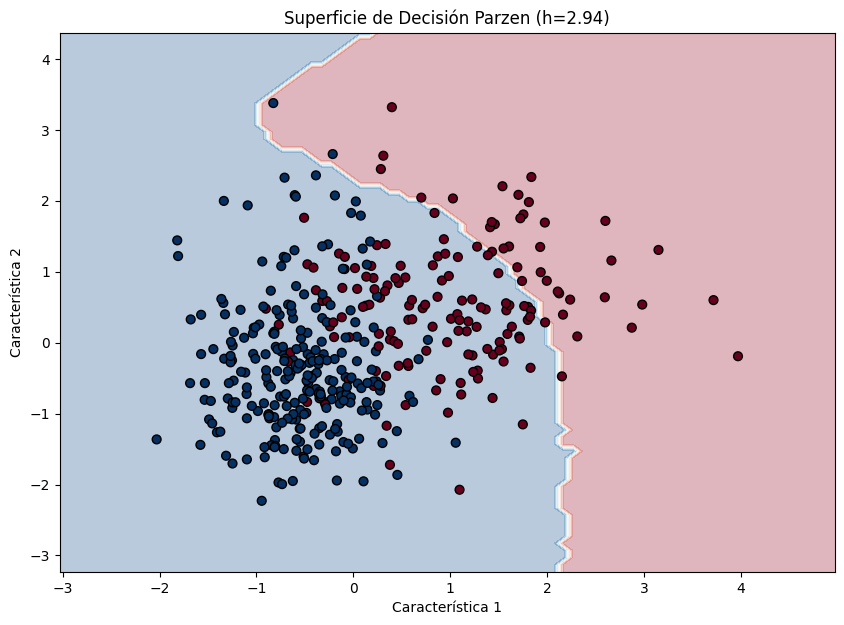

In [ ]:
# --- VISUALIZACIÓN DE SUPERFICIE ---

def plot_parzen_boundary_fixed(train_df, h_value):
    X = train_df.iloc[:, :2].values # Usamos las primeras 2 columnas para el plano
    y = train_df['Class'].values

    # Malla para el fondo
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = []

    # Datos 2D para que el clasificador funcione en la gráfica
    training_data_2D = np.column_stack((X, y)).tolist()

    for pt in grid_points:
        # Placeholder de clase [0] al final del punto
        res = parzenWindowClassifier(training_data_2D, pt.tolist() + [0], h_value)

        # Si es None, buscamos el color del vecino más cercano
        if res is None:
            v_knn = getNeighbors(training_data_2D, pt.tolist() + [0], k=1)
            res = getResponse(v_knn)
        Z.append(res)

    Z = np.array(Z).reshape(xx.shape)

    plt.figure(figsize=(10, 7))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', s=40, cmap='RdBu') # Puntos reales
    plt.title(f"Superficie de Decisión Parzen (h={h_value:.2f})")
    plt.xlabel("Característica 1")
    plt.ylabel("Característica 2")
    plt.show()

plot_parzen_boundary_fixed(train, h_final_parzen)

***Cálculo de matriz de confusión***

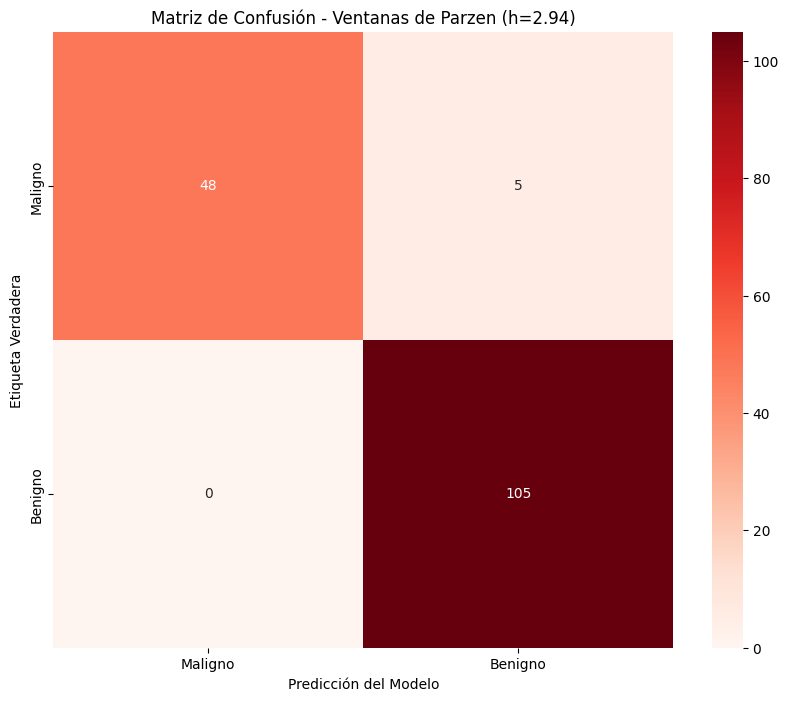

--- Reporte de Desempeño: Ventanas de Parzen ---
              precision    recall  f1-score   support

     Maligno       1.00      0.91      0.95        53
     Benigno       0.95      1.00      0.98       105

    accuracy                           0.97       158
   macro avg       0.98      0.95      0.96       158
weighted avg       0.97      0.97      0.97       158



In [ ]:
# Definir el conjunto de prueba
test_data = test.values.tolist()
train_data = train.values.tolist()

# Usamos una caída a KNN (k=1) si la ventana de Parzen queda vacía en zonas de baja densidad
h_optimo = h_final_parzen
predicciones_parzen = [
    parzenWindowClassifier(train_data, x_test, h_optimo) or getResponse(getNeighbors(train_data, x_test, k=1))
    for x_test in test_data
]

# Obtener las etiquetas reales
etiquetas_reales = [x[-1] for x in test_data]
# Calcular y graficar la Matriz de Confusión
cm_parzen = confusion_matrix(etiquetas_reales, predicciones_parzen)
plt.figure(figsize=(10,8))
sns.heatmap(cm_parzen, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Maligno', 'Benigno'],
            yticklabels=['Maligno', 'Benigno'])
plt.title(f'Matriz de Confusión - Ventanas de Parzen (h={h_optimo:.2f})')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Etiqueta Verdadera')
plt.show()

# Mostrar reporte de métricas
print("--- Reporte de Desempeño: Ventanas de Parzen ---")
print(classification_report(etiquetas_reales, predicciones_parzen, target_names=['Maligno', 'Benigno']))

***Visualización de la Distribución de Clases mediante KDE***

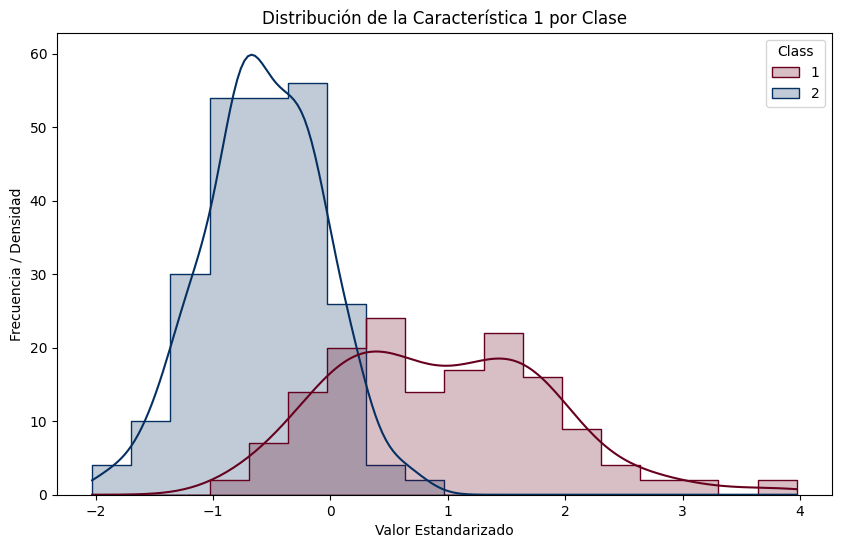

In [ ]:
plt.figure(figsize=(10, 6))
# Histogramas de la primera característica separados por clase
sns.histplot(data=train, x=train.columns[0], hue='Class', kde=True, element="step", palette='RdBu')
plt.title("Distribución de la Característica 1 por Clase")
plt.xlabel("Valor Estandarizado")
plt.ylabel("Frecuencia / Densidad")
plt.show()